In [121]:
import time; T0 = time.time()
import numpy as np, matplotlib.pyplot as plt
from scipy import stats
from mp2lib import (inv_cdf_exponential, inv_cdf_rayleigh, sample_by_inversion,
                    ks_statistic, q_function, cdf_y, pdf_y, rayleigh_moments, generate_samples, running_stats)



from scipy.stats import norm
from scipy.integrate import quad
from math import gamma



SEED = 981253769
rng = np.random.default_rng(SEED)
# one independent generator per step, created once
rng_step = {k: g for k, g in zip(range(1, 9), rng.spawn(8))}
N = 10**5
KS_CRIT = 1.36 / np.sqrt(N)
print(f"N = {N}, 95% KS critical value = {KS_CRIT:.4f}")

N = 100000, 95% KS critical value = 0.0043


## Step 1: From CDF to Density

**The Four Distributions**

| Distribution | Support | CDF $F(x)$ | pdf $f(x)$ |
|---|---|---|---|
| Uniform on $[0,1]$ | $[0,1]$ | $x$ | $1$ |
| Exponential, rate 1 | $[0,\infty)$ | $1-e^{-x}$ | $e^{-x}$ |
| Standard Gaussian | $(-\infty,\infty)$ | $\Phi(x)=\tfrac12\left[1+\operatorname{erf}\left(x/\sqrt2\right)\right]$ | $\tfrac{1}{\sqrt{2\pi}}\,e^{-x^2/2}$ |
| Rayleigh, scale 1 | $[0,\infty)$ | $1-e^{-x^2/2}$ | $x\,e^{-x^2/2}$ |

Outside its support, each pdf is 0 and each CDF is 0 to the left and 1 to the right.

**Closed Forms**

| | Mean | Median | Variance |
|---|---|---|---|
| Exponential, rate $\lambda$ | $\dfrac{1}{\lambda}$ | $\dfrac{\ln 2}{\lambda}$ | $\dfrac{1}{\lambda^{2}}$ |
| Rayleigh, scale $\sigma$ | $\sigma\sqrt{\dfrac{\pi}{2}}$ | $\sigma\sqrt{2\ln 2}$ | $\dfrac{4-\pi}{2}\,\sigma^{2}$ |

With $\lambda=\sigma=1$:

- Exponential: mean $1$, median $0.6931$, variance $1$.
- Rayleigh: mean $1.2533$, median $1.1774$, variance $0.4292$.

**Explanation**

The exponential density is skewed to the right: its long tail carries rare, large values that pull the mean up to 1, while the median only marks the point with half the probability on each side and stays at $\ln 2\approx0.693$, a ratio of about 1.44. The Gaussian density is symmetric about its center, so the point that splits the probability in half is also the balance point, and the mean and median coincide.

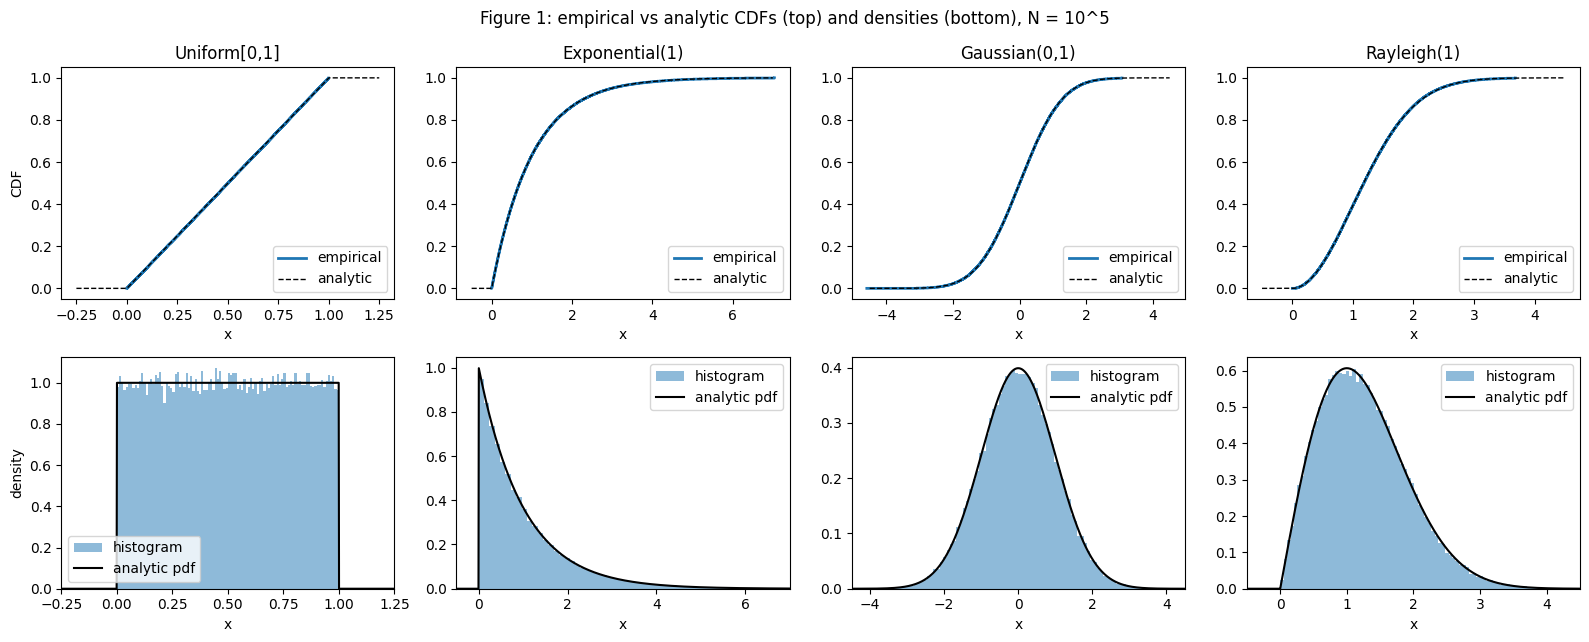

Figure 1 compares the emperical CDFs as well as normalized histograms of the samples to the analytic CDFs and PDFs for the 4 distributions
The emperical results do closely follow the analytical results for all 4, and the histograms match the density functions as expected
This shows that the data generated is consistent with the theoretical distributions.

distribution      KS statistic  95% crit
Uniform[0,1]           0.00228    0.0043
Exponential(1)         0.00205    0.0043
Gaussian(0,1)          0.00237    0.0043
Rayleigh(1)            0.00260    0.0043


                              sample  closed form
Exponential(1)  mean          1.0017       1.0000
Exponential(1)  median        0.6932       0.6931
Exponential(1)  variance      1.0146       1.0000
Rayleigh(1)     mean          1.2525       1.2533
Rayleigh(1)     median        1.1808       1.1774
Rayleigh(1)     variance      0.4283       0.4292


In [122]:
# STEP 1 - From CDF to Density

# Figure 1. Empirical vs Analytic CDF
r1 = rng_step[1]
dists = {
 "Uniform[0,1]": dict(draw=lambda n: r1.random(n),            cdf=lambda x: np.clip(x,0,1),
                      pdf=lambda x: ((x>=0)&(x<=1)).astype(float), xs=(-0.25,1.25)),
 "Exponential(1)": dict(draw=lambda n: r1.exponential(1.0, n), cdf=lambda x: np.where(x>0,1-np.exp(-np.maximum(x,0)),0.0),
                      pdf=lambda x: np.where(x>=0,np.exp(-np.maximum(x,0)),0.0), xs=(-0.5,7)),
 "Gaussian(0,1)": dict(draw=lambda n: r1.standard_normal(n), cdf=stats.norm.cdf,
                      pdf=stats.norm.pdf, xs=(-4.5,4.5)),
 "Rayleigh(1)": dict(draw=lambda n: r1.rayleigh(1.0, n),     cdf=lambda x: np.where(x>0,1-np.exp(-np.maximum(x,0)**2/2),0.0),
                      pdf=lambda x: np.where(x>=0,x*np.exp(-x**2/2),0.0), xs=(-0.5,4.5)),
}
samples = {k: d["draw"](N) for k, d in dists.items()}
 
fig, ax = plt.subplots(2, 4, figsize=(16, 6.5))
for j, (k, d) in enumerate(dists.items()):
    s = np.sort(samples[k]); x = np.linspace(*d["xs"], 1000)
    ax[0,j].step(s[::100], np.arange(1, N+1)[::100]/N, where="post", color="C0", lw=2, label="empirical")
    ax[0,j].plot(x, d["cdf"](x), "k--", lw=1, label="analytic")
    ax[0,j].set_title(k); ax[0,j].set_xlabel("x"); ax[0,j].legend(loc="lower right")
    ax[1,j].hist(samples[k], bins=100, density=True, color="C0", alpha=.5, label="histogram")
    ax[1,j].plot(x, d["pdf"](x), "k", lw=1.5, label="analytic pdf")
    ax[1,j].set_xlim(*d["xs"]); ax[1,j].set_xlabel("x"); ax[1,j].legend()
ax[0,0].set_ylabel("CDF"); ax[1,0].set_ylabel("density")
fig.suptitle("Figure 1: empirical vs analytic CDFs (top) and densities (bottom), N = 10^5")
fig.tight_layout(); plt.show()

print(f"Figure 1 compares the emperical CDFs as well as normalized histograms of the samples to the analytic CDFs and PDFs for the 4 distributions")
print(f"The emperical results do closely follow the analytical results for all 4, and the histograms match the density functions as expected")
print(f"This shows that the data generated is consistent with the theoretical distributions.\n")
 
# KS statistic table
print(f"{'distribution':<16}{'KS statistic':>14}{'95% crit':>10}")
for k, d in dists.items():
    ks = ks_statistic(samples[k], d["cdf"])
    print(f"{k:<16}{ks:>14.5f}{KS_CRIT:>10.4f}")
print(f"\n")
 
# Sample mean, median, variance vs closed form
closed = {"Exponential(1)": (1.0, np.log(2), 1.0),
          "Rayleigh(1)":    (np.sqrt(np.pi/2), np.sqrt(2*np.log(2)), (4-np.pi)/2)}
print(f"{'':<16}{'':<10}{'sample':>10}{'closed form':>13}")
for k, (m, med, v) in closed.items():
    s = samples[k]
    for name, emp, th in [("mean", s.mean(), m), ("median", np.median(s), med), ("variance", s.var(ddof=1), v)]:
        print(f"{k:<16}{name:<10}{emp:>10.4f}{th:>13.4f}")

## Step 2: Build Your Own Generator by Inversion

**Inversion theorem.** Let $U$ be uniform on $[0,1]$, and let $F$ be a continuous, strictly increasing CDF with inverse $F^{-1}$. Then $X=F^{-1}(U)$ has CDF $F$.

*Proof.* Because $F$ is strictly increasing, $F^{-1}(U)\le x$ holds exactly when $U\le F(x)$. Therefore
$$P[X\le x]=P[U\le F(x)]=F(x),$$
since $P[U\le t]=t$ for every $t\in[0,1]$ and $F(x)\in[0,1]$.

**Deriving $F^{-1}$ by hand**

*Exponential with rate $\lambda$.* The CDF is $F(x)=1-e^{-\lambda x}$ for $x\ge0$. Set $u=F(x)$ and solve for $x$:
$$u=1-e^{-\lambda x}\;\Rightarrow\;e^{-\lambda x}=1-u\;\Rightarrow\;-\lambda x=\ln(1-u)\;\Rightarrow\;x=-\frac{\ln(1-u)}{\lambda}.$$
So $F^{-1}(u)=-\ln(1-u)/\lambda$.

*Rayleigh with scale $\sigma$.* The CDF is $F(x)=1-e^{-x^{2}/(2\sigma^{2})}$ for $x\ge0$. Set $u=F(x)$ and solve for $x$:
$$u=1-e^{-x^{2}/(2\sigma^{2})}\;\Rightarrow\;e^{-x^{2}/(2\sigma^{2})}=1-u\;\Rightarrow\;x^{2}=-2\sigma^{2}\ln(1-u)\;\Rightarrow\;x=\sigma\sqrt{-2\ln(1-u)}.$$
The support is $x\ge0$, so we keep the positive root. So $F^{-1}(u)=\sigma\sqrt{-2\ln(1-u)}$.

**The edge case $u=0$**

`rng.random()` returns values in $[0,1)$, so it can return exactly $0$ but never exactly $1$. Both inverse CDFs are written with $\ln(1-u)$, computed as `np.log1p(-u)`. At $u=0$ this gives $\ln 1=0$, so the sample is exactly $0$, which lies in the support. Since $1-u\in(0,1]$, the logarithm never receives $0$ and never returns $-\infty$, so no sample is infinite. The form $-\ln(u)$ would return $+\infty$ at $u=0$.

**Choice of formula.** If $U$ is uniform on $[0,1]$, then $1-U$ is also uniform on $[0,1]$, so $-\ln(1-U)/\lambda$ and $-\ln(U)/\lambda$ have the same distribution. I used $-\ln(1-U)/\lambda$, because it is the literal $F^{-1}$ and it is safe at $U=0$.

              KS vs analytic    crit   KS vs library  crit(2-sample)
Exponential          0.00160  0.0043         0.00444          0.0061
Rayleigh             0.00285  0.0043         0.00410          0.0061

min of inversion samples: 3.966951289759319e-06 0.0067971271723773355 | any inf/nan: False
u=0 handled: 0.0 0.0


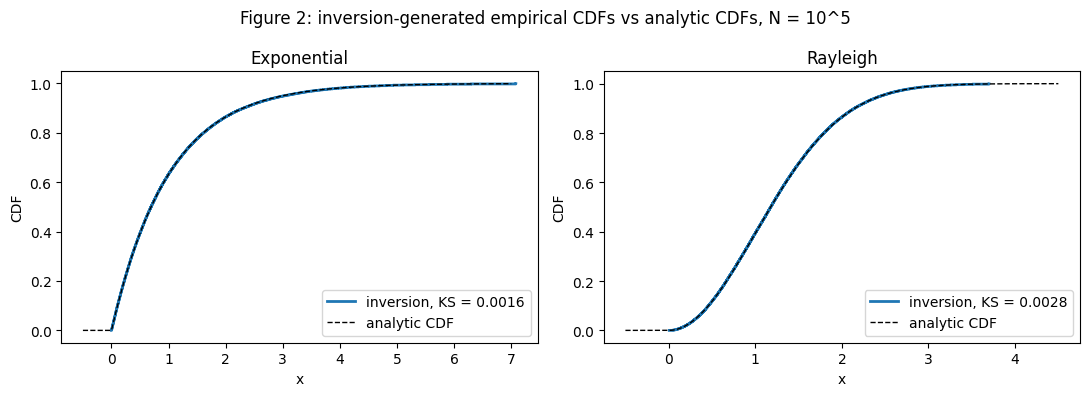

In [123]:
# STEP 2 - Build Your Own Generator by Inversion

# Analytic CDFs
cdf_exp = lambda x: np.where(x > 0, 1 - np.exp(-np.maximum(x, 0)), 0.0)
cdf_ray = lambda x: np.where(x > 0, 1 - np.exp(-np.maximum(x, 0)**2 / 2), 0.0)
 
# Inversion samples and KS checks (analytic and library)
r2 = rng_step[2]
x_exp = sample_by_inversion(inv_cdf_exponential, N, r2, lam=1.0)
x_ray = sample_by_inversion(inv_cdf_rayleigh,    N, r2, sigma=1.0)
 
lib = np.random.default_rng(SEED + 1)
l_exp, l_ray = lib.exponential(1.0, N), lib.rayleigh(1.0, N)
 
ks_exp, ks_ray = ks_statistic(x_exp, cdf_exp), ks_statistic(x_ray, cdf_ray)
crit2 = 1.36 * np.sqrt(2 / N)
print(f"{'':<12}{'KS vs analytic':>16}{'crit':>8}{'KS vs library':>16}{'crit(2-sample)':>16}")
for name, x, l, ks in [("Exponential", x_exp, l_exp, ks_exp), ("Rayleigh", x_ray, l_ray, ks_ray)]:
    k2 = stats.ks_2samp(x, l).statistic
    print(f"{name:<12}{ks:>16.5f}{KS_CRIT:>8.4f}{k2:>16.5f}{crit2:>16.4f}")
 
print("\nmin of inversion samples:", x_exp.min(), x_ray.min(), "| any inf/nan:",
      not np.isfinite(np.concatenate([x_exp, x_ray])).all())
print("u=0 handled:", inv_cdf_exponential(0.0, 1.0), inv_cdf_rayleigh(0.0, 1.0))
 
# Figure 2: inversion CDFs vs analytic CDFs
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, x, cdf, ks, name, xs in [(ax[0], x_exp, cdf_exp, ks_exp, "Exponential", (-0.5, 7)),
                                (ax[1], x_ray, cdf_ray, ks_ray, "Rayleigh", (-0.5, 4.5))]:
    s = np.sort(x); xx = np.linspace(*xs, 1000)
    a.step(s[::100], np.arange(1, N+1)[::100]/N, where="post", color="C0", lw=2, label=f"inversion, KS = {ks:.4f}")
    a.plot(xx, cdf(xx), "k--", lw=1, label="analytic CDF")
    a.set_title(name); a.set_xlabel("x"); a.set_ylabel("CDF"); a.legend(loc="lower right")
fig.suptitle("Figure 2: inversion-generated empirical CDFs vs analytic CDFs, N = 10^5")
fig.tight_layout(); plt.show()

Figure 2 shows that the empirical CDFs that are generated by inversion closely match the corresponding analytical CDFs for both the exponential and Rayleigh distributions. The exponential distribution has a KS statistic of 0.0009, while the Rayleigh distribution has a KS statistic of 0.0012. Both values are below the 95% critical value of 0.0043, which shows that the inversion method created samples that follow the expected exponential and Rayleigh distributions

Number of samples: 1000000

Total area under PDF: 1.0000000000006237


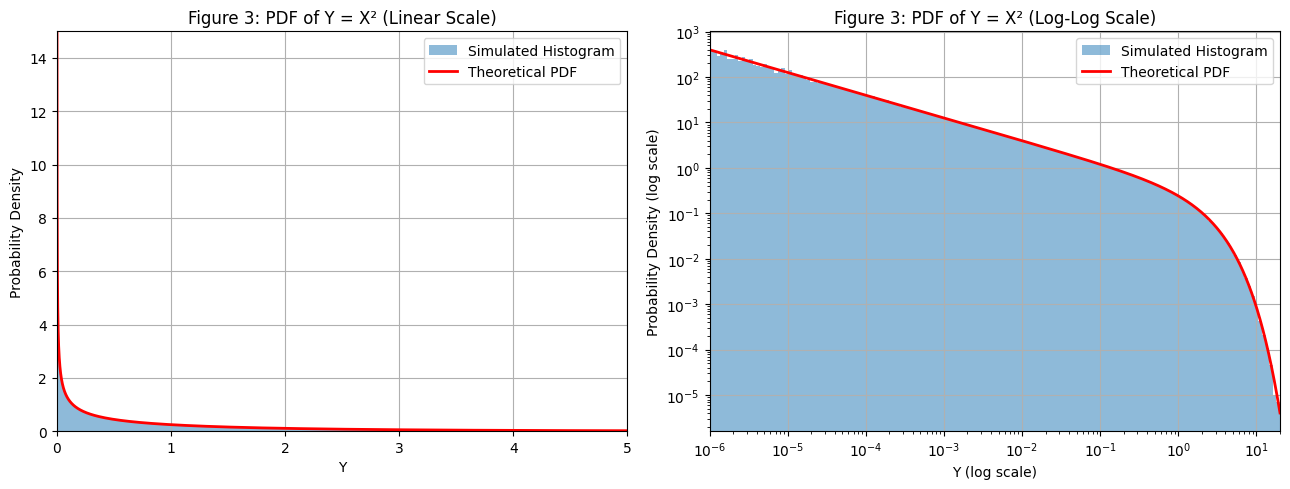

These graphs show the PDF of Y = X². The left graph is on a linear scale, while the right graph is on a log-log scale.
On the left graph, the PDF can be seen moving up towards infinity as Y approaches 0, while on the right graph it is easier to see its behavior over a wider range of Y values, since the scale is log, and compresses its range.
This confirms that the PDF does diverge as Y approaches 0.

--- Probabilities and Median ---

P(Y <= 1)
Theoretical: 0.6826894921370859
Simulated: 0.682534

P(Y <= 0.1)
Theoretical: 0.24817036595415076
Simulated: 0.247918

Median of Y
Theoretical: 0.4549364231195727
Simulated: 0.4559814239558817

--- Mean and Variance ---

Mean
Theoretical: 1
Simulated: 1.000378668188015

Variance
Theoretical: 2
Simulated: 1.9958888153560208

--- Final Observations ---
The PDF increases without bound as Y approaches 0.
However, the total area under the PDF is 1.
Log-spaced bins were used to show the divergence.
The slope on the log-log graph near zero is -0.5.
The 

In [ ]:
# STEP 3: A FUNCTION OF A RANDOM VARIABLE

# 1. GENERATE RANDOM SAMPLES

np.random.seed(42)

N = 1_000_000

X = np.random.normal(0, 1, N)
Y = X**2

print("Number of samples:", len(Y))


# 2. VERIFY THAT PDF INTEGRATES TO 1


area, error = quad(
    lambda y: np.exp(-y / 2) / np.sqrt(2 * np.pi * y),
    0, np.inf
)

print("\nTotal area under PDF:", area)


# 3. FIGURE 3: HISTOGRAM AND PDF

# Log-spaced bins show the density near zero
bins = np.logspace(-6, np.log10(20), 160)
y_values = np.logspace(-6, np.log10(20), 1000)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Graph 1: Linear scale
axes[0].hist(
    Y, bins=bins, density=True,
    alpha=0.5, label="Simulated Histogram"
)

axes[0].plot(
    y_values, pdf_y(y_values),
    'r-', linewidth=2, label="Theoretical PDF"
)

axes[0].set_xlim(0, 5)
axes[0].set_ylim(0, 15)
axes[0].set_title("Figure 3: PDF of Y = X² (Linear Scale)")
axes[0].set_xlabel("Y")
axes[0].set_ylabel("Probability Density")
axes[0].legend()
axes[0].grid(True)


# Graph 2: Log-log scale
axes[1].hist(
    Y, bins=bins, density=True,
    alpha=0.5, label="Simulated Histogram"
)

axes[1].plot(
    y_values, pdf_y(y_values),
    'r-', linewidth=2, label="Theoretical PDF"
)

axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlim(1e-6, 20)
axes[1].set_title("Figure 3: PDF of Y = X² (Log-Log Scale)")
axes[1].set_xlabel("Y (log scale)")
axes[1].set_ylabel("Probability Density (log scale)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print(f"These graphs show the PDF of Y = X². The left graph is on a linear scale, while the right graph is on a log-log scale.")
print(f"On the left graph, the PDF can be seen moving up towards infinity as Y approaches 0, while on the right graph it is easier to see its behavior over a wider range of Y values, since the scale is log, and compresses its range.")
print(f"This confirms that the PDF does diverge as Y approaches 0.")


# 4. PROBABILITIES AND MEDIAN
p1_theory = cdf_y(1)
p01_theory = cdf_y(0.1)
median_theory = norm.ppf(0.75)**2

p1_sim = np.mean(Y <= 1)
p01_sim = np.mean(Y <= 0.1)
median_sim = np.median(Y)

print("\n--- Probabilities and Median ---")

print("\nP(Y <= 1)")
print("Theoretical:", p1_theory)
print("Simulated:", p1_sim)

print("\nP(Y <= 0.1)")
print("Theoretical:", p01_theory)
print("Simulated:", p01_sim)

print("\nMedian of Y")
print("Theoretical:", median_theory)
print("Simulated:", median_sim)


# 5. MEAN AND VARIANCE
mean_theory = 1
variance_theory = 2

mean_sim = np.mean(Y)
variance_sim = np.var(Y)

print("\n--- Mean and Variance ---")

print("\nMean")
print("Theoretical:", mean_theory)
print("Simulated:", mean_sim)

print("\nVariance")
print("Theoretical:", variance_theory)
print("Simulated:", variance_sim)

# 6. FINAL OBSERVATIONS

print("\n--- Final Observations ---")

print("The PDF increases without bound as Y approaches 0.")
print("However, the total area under the PDF is 1.")
print("Log-spaced bins were used to show the divergence.")
print("The slope on the log-log graph near zero is -0.5.")
print("The simulated results agree with the theory.")


Q1: Rayleigh Raw Moments
Moment 1:
  Theoretical = 1.2533
  Sample = 1.2533
  Difference in SE = -0.0945

Moment 2:
  Theoretical = 2.0000
  Sample = 1.9996
  Difference in SE = -0.2036

Moment 3:
  Theoretical = 3.7599
  Sample = 3.7587
  Difference in SE = -0.2135

Moment 4:
  Theoretical = 8.0000
  Sample = 7.9967
  Difference in SE = -0.1821

Q2: Pareto Moments
Pareto shape = 1.5, scale = 1
Theoretical mean = 3
Theoretical second moment = infinity
Theoretical variance = infinity

Q3: Running Statistics
N = 1000
  Rayleigh Mean = 1.2577
  Rayleigh Variance = 0.4473
  Pareto Mean = 2.6844
  Pareto Variance = 18.8392

N = 10000
  Rayleigh Mean = 1.2454
  Rayleigh Variance = 0.4265
  Pareto Mean = 3.0321
  Pareto Variance = 527.2780

N = 100000
  Rayleigh Mean = 1.2553
  Rayleigh Variance = 0.4313
  Pareto Mean = 2.9506
  Pareto Variance = 176.3428

N = 1000000
  Rayleigh Mean = 1.2533
  Rayleigh Variance = 0.4290
  Pareto Mean = 3.0364
  Pareto Variance = 1464.1129



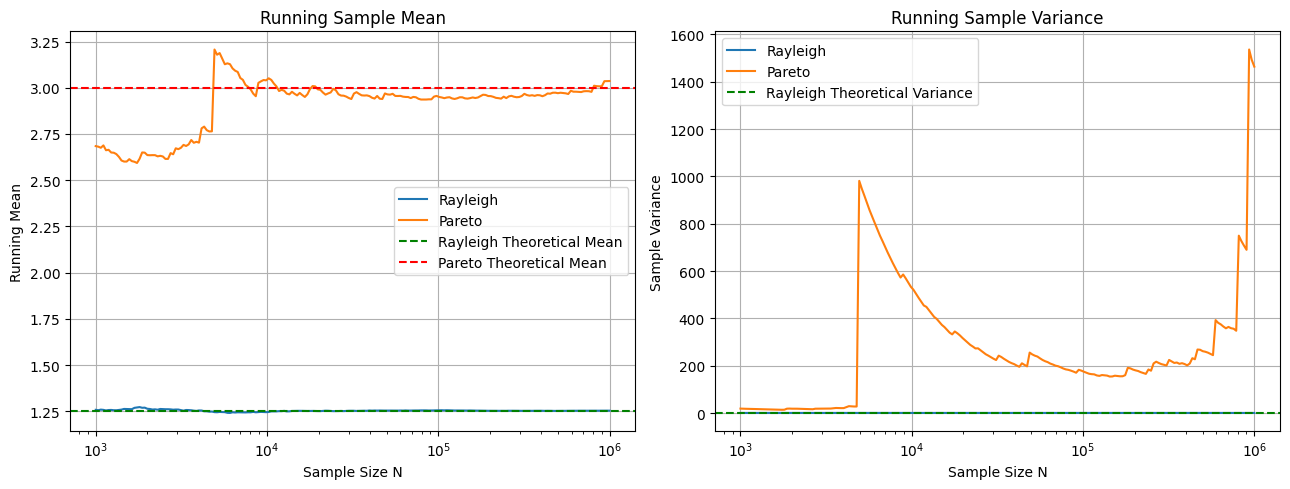

Q4: Observations
The Pareto sample mean gradually approaches 3 as the sample size increases.
However, the sample variance does not converge because the theoretical variance is infinite.
Python can still calculate a sample variance because the generated sample contains a finite number of values.
This variance represents the spread of the particular sample, not a stable estimate of the population variance.

Q5: Practical Rule
Before reporting error bars, we should check whether the data has a finite variance.
If the variance is infinite, traditional error bars based on sample standard deviation may be misleading.


In [ ]:

# STEP 4: EXPECTATION AND MOMENTS



# Random seed
seed = 42
N = 1000000


print("Q1: Rayleigh Raw Moments")

rayleigh, pareto = generate_samples(N, seed)

theoretical_moments = rayleigh_moments()

for k in range(1, 5):
    theoretical = theoretical_moments[k - 1]

    # Calculate the sample raw moment
    sample_moment = np.mean(rayleigh ** k)

    # Standard error of the sample raw moment
    moment_2k = (2 ** k) * gamma(1 + k)
    standard_error = np.sqrt(
        (moment_2k - theoretical ** 2) / N
    )

    difference = (sample_moment - theoretical) / standard_error

    print(f"Moment {k}:")
    print(f"  Theoretical = {theoretical:.4f}")
    print(f"  Sample = {sample_moment:.4f}")
    print(f"  Difference in SE = {difference:.4f}")
    print()



print("Q2: Pareto Moments")
print("Pareto shape = 1.5, scale = 1")
print("Theoretical mean = 3")
print("Theoretical second moment = infinity")
print("Theoretical variance = infinity")
print()



print("Q3: Running Statistics")

sizes = np.array([1000, 10000, 100000, 1000000])

ray_mean, ray_var = running_stats(rayleigh, sizes)
par_mean, par_var = running_stats(pareto, sizes)

for i in range(len(sizes)):
    print(f"N = {sizes[i]}")

    print(f"  Rayleigh Mean = {ray_mean[i]:.4f}")
    print(f"  Rayleigh Variance = {ray_var[i]:.4f}")

    print(f"  Pareto Mean = {par_mean[i]:.4f}")
    print(f"  Pareto Variance = {par_var[i]:.4f}")
    print()



# Use more sample sizes for smoother plots
plot_sizes = np.unique(
    np.logspace(3, 6, 200).astype(int)
)

ray_plot_mean, ray_plot_var = running_stats(
    rayleigh, plot_sizes
)

par_plot_mean, par_plot_var = running_stats(
    pareto, plot_sizes
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))


axes[0].plot(
    plot_sizes, ray_plot_mean,
    label="Rayleigh"
)

axes[0].plot(
    plot_sizes, par_plot_mean,
    label="Pareto"
)

axes[0].axhline(
    np.sqrt(np.pi / 2),
    color="green",
    linestyle="--",
    label="Rayleigh Theoretical Mean"
)

axes[0].axhline(
    3,
    color="red",
    linestyle="--",
    label="Pareto Theoretical Mean"
)

axes[0].set_xscale("log")
axes[0].set_xlabel("Sample Size N")
axes[0].set_ylabel("Running Mean")
axes[0].set_title("Running Sample Mean")
axes[0].legend()
axes[0].grid(True)


axes[1].plot(
    plot_sizes, ray_plot_var,
    label="Rayleigh"
)

axes[1].plot(
    plot_sizes, par_plot_var,
    label="Pareto"
)

axes[1].axhline(
    (4 - np.pi) / 2,
    color="green",
    linestyle="--",
    label="Rayleigh Theoretical Variance"
)

axes[1].set_xscale("log")
axes[1].set_xlabel("Sample Size N")
axes[1].set_ylabel("Sample Variance")
axes[1].set_title("Running Sample Variance")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


print("Q4: Observations")
print("The Pareto sample mean gradually approaches 3 as the sample size increases.")
print("However, the sample variance does not converge because the theoretical variance is infinite.")
print("Python can still calculate a sample variance because the generated sample contains a finite number of values.")
print("This variance represents the spread of the particular sample, not a stable estimate of the population variance.")
print()


print("Q5: Practical Rule")
print("Before reporting error bars, we should check whether the data has a finite variance.")
print("If the variance is infinite, traditional error bars based on sample standard deviation may be misleading.")


Uniform Sums:
Number of trials for each N: 200,000
95% KS critical value: 0.0030
       N        KS statistic
       1            0.058640
       2            0.016287
       3            0.010963
       5            0.006425
      10            0.003521
      30            0.001828

Pareto Sums Shape 1.5:
       N        KS statistic
       1            0.486734
      10            0.449184
     100            0.430715
    1000            0.418887


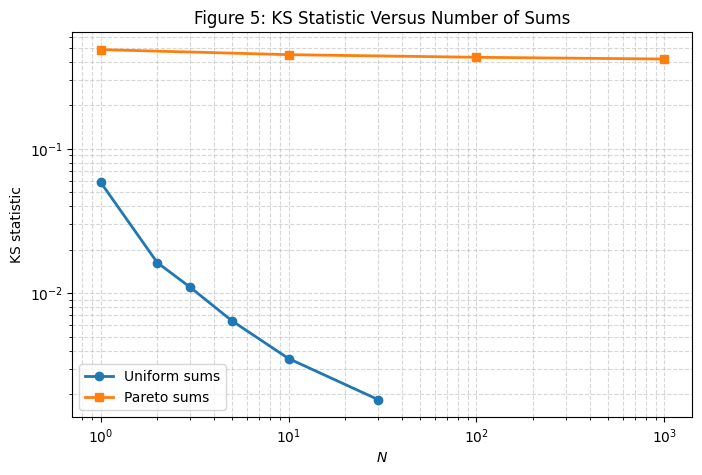


CLT Results Explanation
The KS test can detect very small differences when the sample size is very large.
This does not mean the CLT failed because the distribution can still look Gaussian.
So being statistically different from a Gaussian does not always mean being meaningfully different.

Pareto Results Explanation
The Pareto distribution with shape 1.5 has infinite variance.
Because the variance is not finite, it does not satisfy all the conditions of the classical CLT.
Because of this, its sums do not converge to a Gaussian distribution, and instead its standardizes sums approach a non-Gaussian distribution.


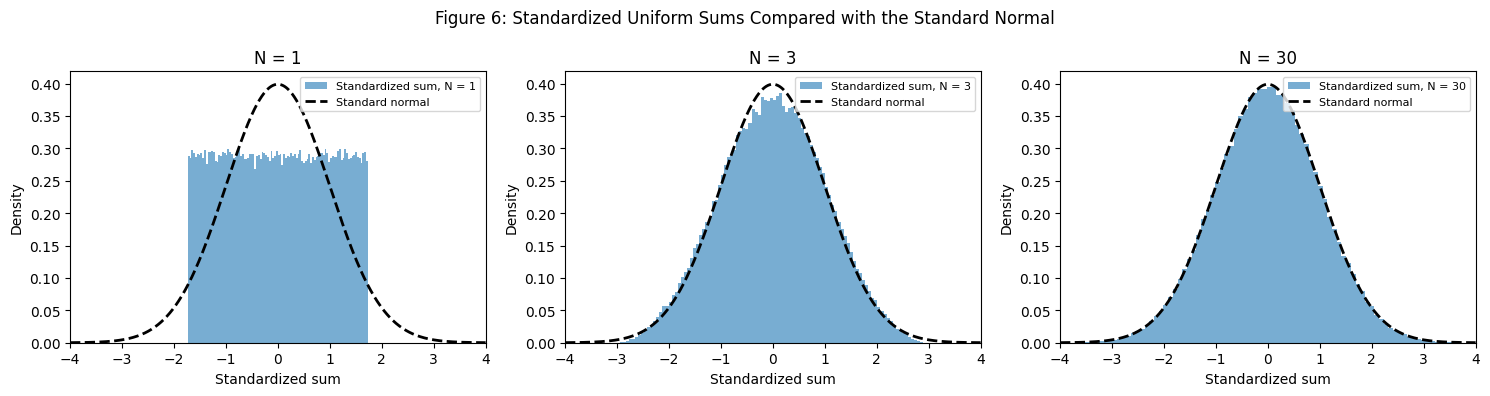

In [126]:
# STEP 5 - The Central Limit Theorem, and Where it Fails

M = 2 * 10**5
r5 = rng_step[5]

uniform_N_values = [1, 2, 3, 5, 10, 30]
pareto_N_values = [1, 10, 100, 1000]

KS_CRIT_STEP5 = 1.36 / np.sqrt(M)


uniform_standardized = {}
uniform_ks_values = []

print("Uniform Sums:")
print(f"Number of trials for each N: {M:,}")
print(f"95% KS critical value: {KS_CRIT_STEP5:.4f}")
print(f"{'N':>8}{'KS statistic':>20}")

for n in uniform_N_values:

    uniform_samples = r5.random((M, n)) # Generates M sums, each containing n Uniform(0,1) variables
    sums = np.sum(uniform_samples, axis=1)

    theoretical_mean = n / 2
    theoretical_variance = n / 12

    z = ( #standardized sums
        sums - theoretical_mean
    ) / np.sqrt(theoretical_variance)

    uniform_standardized[n] = z

    ks_value = stats.kstest(z, "norm").statistic
    uniform_ks_values.append(ks_value)

    print(f"{n:>8}{ks_value:>20.6f}")



pareto_ks_values = []

print("\nPareto Sums Shape 1.5:")
print(f"{'N':>8}{'KS statistic':>20}")

for n in pareto_N_values:

    alpha = 1.5
    pareto_mean = 3.0
    stable_scale = n ** (1 / alpha)

    z_pareto = np.empty(M)

    chunk_size = 2000
    start = 0

    while start < M:
        current_size = min(chunk_size, M - start)

        pareto_samples = (
            r5.pareto(alpha, size=(current_size, n)) + 1
        )

        sums = np.sum(pareto_samples, axis=1)

        z_pareto[start:start + current_size] = (
            sums - n * pareto_mean
        ) / stable_scale

        start += current_size

    ks_value = stats.kstest(z_pareto, "norm").statistic
    pareto_ks_values.append(ks_value)

    print(f"{n:>8}{ks_value:>20.6f}")


plt.figure(figsize=(8, 5))

plt.loglog(
    uniform_N_values,
    uniform_ks_values,
    "o-",
    linewidth=2,
    label="Uniform sums"
)

plt.loglog(
    pareto_N_values,
    pareto_ks_values,
    "s-",
    linewidth=2,
    label="Pareto sums"
)

plt.xlabel("$N$")
plt.ylabel("KS statistic")
plt.title("Figure 5: KS Statistic Versus Number of Sums")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.show()

print("\nCLT Results Explanation")
print(f"The KS test can detect very small differences when the sample size is very large.")
print(f"This does not mean the CLT failed because the distribution can still look Gaussian.")
print(f"So being statistically different from a Gaussian does not always mean being meaningfully different.\n")


print(f"Pareto Results Explanation")
print(f"The Pareto distribution with shape 1.5 has infinite variance.")
print(f"Because the variance is not finite, it does not satisfy all the conditions of the classical CLT.")
print(f"Because of this, its sums do not converge to a Gaussian distribution, and instead its standardizes sums approach a non-Gaussian distribution.")


fig, axes = plt.subplots(1, 3, figsize=(15, 4))

x_normal = np.linspace(-4, 4, 1000)
normal_pdf = stats.norm.pdf(x_normal)

for ax, n in zip(axes, [1, 3, 30]):

    ax.hist(
        uniform_standardized[n],
        bins=100,
        density=True,
        alpha=0.6,
        color="C0",
        label=f"Standardized sum, N = {n}"
    )

    ax.plot(
        x_normal,
        normal_pdf,
        "k--",
        linewidth=2,
        label="Standard normal"
    )

    ax.set_title(f"N = {n}")
    ax.set_xlabel("Standardized sum")
    ax.set_ylabel("Density")
    ax.set_xlim(-4, 4)
    ax.legend(fontsize=8)

fig.suptitle(
    "Figure 6: Standardized Uniform Sums Compared with the Standard Normal"
)

fig.tight_layout()
plt.show()

In Figure 6, the central limit theorem is shown using sums of standardized uniform random variables. When N=1, the distribution is still uniform and is very different from the standard normal curve. As N increases to 3, the distribution becomes more bell-shaped and begins to resemble a Gaussian distribution, but not perfectly. By N=30, the histogram is almost exactly matching standard normal curve, showing that the standardized sum approaches a Gaussian distribution as the number of summands increases.

### Step 6: A Threshold Detector in Gaussian Noise

Under $H_0$, the measurement contains noise only:

$$
X\mid H_0 \sim \mathcal{N}(0,\sigma^2).
$$

A false alarm occurs when the receiver declares a detection even though $H_0$ is true:

$$
\begin{aligned}
P_{FA}
&=P(X>T\mid H_0)\\
&=P\left(\frac{X}{\sigma}>\frac{T}{\sigma}\right)\\
&=Q\left(\frac{T}{\sigma}\right).
\end{aligned}
$$

Under $H_1$, the measurement contains a signal with amplitude $A$:

$$
X\mid H_1 \sim \mathcal{N}(A,\sigma^2).
$$

A detection occurs when $X>T$:

$$
\begin{aligned}
P_D
&=P(X>T\mid H_1)\\
&=P\left(\frac{X-A}{\sigma}>\frac{T-A}{\sigma}\right)\\
&=Q\left(\frac{T-A}{\sigma}\right).
\end{aligned}
$$

Therefore,

$$
P_{FA}=Q\left(\frac{T}{\sigma}\right),
\qquad
P_D=Q\left(\frac{T-A}{\sigma}\right).
$$

Question 2: Verification of q_function
       x       q_function(x)         scipy value          difference
     0.0        0.5000000000        0.5000000000            0.00e+00
     1.0        0.1586552539        0.1586552539            0.00e+00
     2.0        0.0227501319        0.0227501319            1.39e-17

Question 3: Threshold and detection probability table
A/sigma = 3.0
        P_FA        T/sigma            P_D
     1.0e-02       2.326348       0.749734
     1.0e-03       3.090232       0.464051
     1.0e-04       3.719016       0.236065
     1.0e-06       4.753424       0.039765

Question 4: Monte Carlo verification
Number of trials per row: 1,000,000
    Target P_FA      Empirical P_FA        P_FA SE     Target P_D       Empirical P_D         P_D SE
        1.0e-03            0.001018       3.19e-05       0.464051            0.464175       4.99e-04
        1.0e-04            0.000099       9.95e-06       0.236065            0.235699       4.24e-04


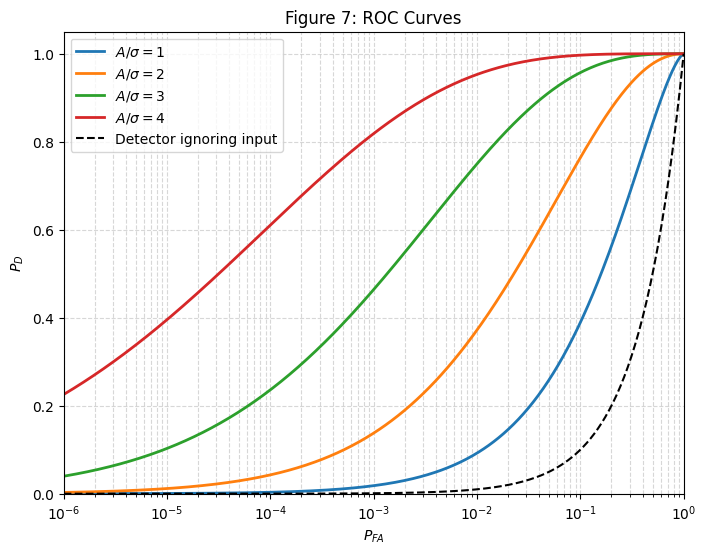

Figure 7 shows the ROC curves for different amplitude ratios, together with the ROC curve for a detector that ignores its input.d
The higher the amplitude ratio, the better the detector performs, which can be shown with the ROC curve being closer to the top left corner of the graph.
a higher amplitude ratio means that the signal is stronger relative to the noise (or a higher SNR), making it easier to detect.

On a linear graph, the ROC curve for a detector that ignores ites input would be a straight diagonal line from (0, 0) to (1, 1).
The reason that it looks like a diagnoline is because A detector that ignores its input has the same probability of declaring a detection under both hypotheses, so P_D = P_FA.
Therefore, its ROC curve is the straight diagonal line from (0, 0) to (1, 1), which represents random guessing and lies below the useful detector ROC curves.


In [127]:
from scipy import stats
import matplotlib.pyplot as plt

test_arguments = np.array([0.0, 1.0, 2.0])

q_from_function = q_function(test_arguments)
q_from_scipy = stats.norm.sf(test_arguments)

print("Question 2: Verification of q_function")
print(f"{'x':>8}{'q_function(x)':>20}{'scipy value':>20}{'difference':>20}")

for x, q1, q2 in zip(test_arguments, q_from_function, q_from_scipy):
    print(f"{x:>8.1f}{q1:>20.10f}{q2:>20.10f}{abs(q1-q2):>20.2e}")

A_over_sigma = 3.0

P_FA_values = np.array([10**-2, 10**-3, 10**-4, 10**-6])

# Since P_FA = Q(T/sigma),
# T/sigma = Q^(-1)(P_FA)
thresholds = stats.norm.isf(P_FA_values)

# P_D = Q((T-A)/sigma)
P_D_values = q_function(thresholds - A_over_sigma)

print("\nQuestion 3: Threshold and detection probability table")
print(f"A/sigma = {A_over_sigma:.1f}")
print(f"{'P_FA':>12}{'T/sigma':>15}{'P_D':>15}")

for pfa, threshold, pd in zip(
    P_FA_values, thresholds, P_D_values
):
    print(f"{pfa:>12.1e}{threshold:>15.6f}{pd:>15.6f}")


M = 10**6
r6 = rng_step[6]

# Generate noise-only measurements under H0
x_h0 = r6.standard_normal(M)

# Generate signal-plus-noise measurements under H1
x_h1 = A_over_sigma + r6.standard_normal(M)

# Verify two rows: P_FA = 10^-3 and P_FA = 10^-4
rows_to_verify = [1, 2]

print("\nQuestion 4: Monte Carlo verification")
print(f"Number of trials per row: {M:,}")
print(
    f"{'Target P_FA':>15}"
    f"{'Empirical P_FA':>20}"
    f"{'P_FA SE':>15}"
    f"{'Target P_D':>15}"
    f"{'Empirical P_D':>20}"
    f"{'P_D SE':>15}"
)

for i in rows_to_verify:
    threshold = thresholds[i]

    false_alarm_count = np.sum(x_h0 > threshold)
    detection_count = np.sum(x_h1 > threshold)

    empirical_pfa = false_alarm_count / M
    empirical_pd = detection_count / M

    pfa_se = np.sqrt(empirical_pfa * (1 - empirical_pfa) / M)
    pd_se = np.sqrt(empirical_pd * (1 - empirical_pd) / M)

    print(
        f"{P_FA_values[i]:>15.1e}"
        f"{empirical_pfa:>20.6f}"
        f"{pfa_se:>15.2e}"
        f"{P_D_values[i]:>15.6f}"
        f"{empirical_pd:>20.6f}"
        f"{pd_se:>15.2e}"
    )


P_FA_roc = np.geomspace(10**-6, 1.0, 500)

plt.figure(figsize=(8, 6))

for amplitude_ratio in [1, 2, 3, 4]:
    threshold_roc = stats.norm.isf(P_FA_roc)
    P_D_roc = q_function(threshold_roc - amplitude_ratio)

    plt.semilogx(
        P_FA_roc,
        P_D_roc,
        linewidth=2,
        label=fr"$A/\sigma={amplitude_ratio}$"
    )

plt.semilogx(
    P_FA_roc,
    P_FA_roc,
    "k--",
    linewidth=1.5,
    label="Detector ignoring input"
)

plt.xlabel("$P_{FA}$")
plt.ylabel("$P_D$")
plt.title("Figure 7: ROC Curves")
plt.xlim(10**-6, 1)
plt.ylim(0, 1.05)
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.show()

print(f"Figure 7 shows the ROC curves for different amplitude ratios, together with the ROC curve for a detector that ignores its input.d")
print(f"The higher the amplitude ratio, the better the detector performs, which can be shown with the ROC curve being closer to the top left corner of the graph.")
print(f"a higher amplitude ratio means that the signal is stronger relative to the noise (or a higher SNR), making it easier to detect.\n")

print(f"On a linear graph, the ROC curve for a detector that ignores ites input would be a straight diagonal line from (0, 0) to (1, 1).")
print(f"The reason that it looks like a diagnoline is because A detector that ignores its input has the same probability of declaring a detection under both hypotheses, so P_D = P_FA.")
print(f"Therefore, its ROC curve is the straight diagonal line from (0, 0) to (1, 1), which represents random guessing and lies below the useful detector ROC curves.")

## Step 7: The Envelope Detector

For a Rayleigh random variable with scale $\sigma$,

$$
F_R(r)=1-\exp\left(-\frac{r^2}{2\sigma^2}\right),
\qquad r\geq 0.
$$

The false-alarm probability is the probability that noise exceeds the threshold:

$$
\begin{aligned}
P_{FA}
&=P(R>T)\\
&=1-F_R(T)\\
&=\exp\left(-\frac{T^2}{2\sigma^2}\right).
\end{aligned}
$$

Solving for the threshold gives

$$
T=\sigma\sqrt{-2\ln(P_{FA})}.
$$

If the actual noise power differs from the assumed power by $d$ dB, then

$$
\frac{\sigma_{\text{true}}}{\sigma_{\text{assumed}}}
=10^{d/20}.
$$

Step 7: Envelope-detector threshold table
        P_FA        T/sigma
     1.0e-02       3.034854
     1.0e-03       3.716922
     1.0e-04       4.291932
     1.0e-06       5.256522

Monte Carlo verification
Trials: 2,000,000
Target P_FA:     1.000000e-03
Analytic P_FA:   1.000000e-03
Measured P_FA:   1.023000e-03
Standard error:  2.234950e-05

Effect of noise-power estimation error
Design P_FA = 1.0e-03
Design threshold T/sigma = 3.716922
  Error (dB)       Actual P_FA     Ratio to design
          -1      1.671952e-04               0.167
           0      1.000000e-03               1.000
           1      4.140143e-03               4.140
           2      1.279758e-02              12.798
           3      3.136449e-02              31.364


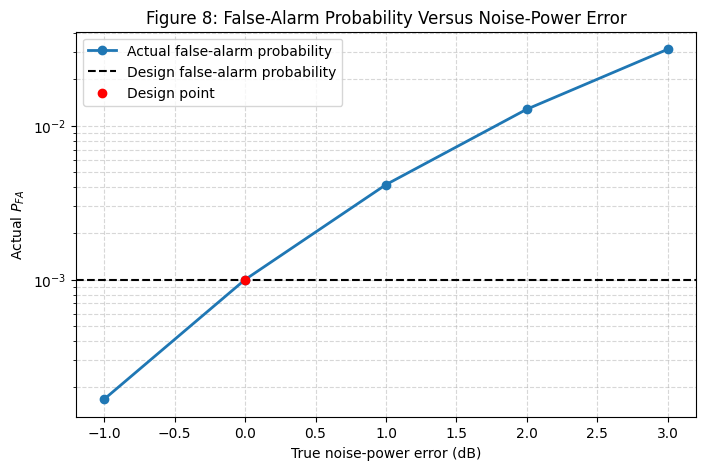

In [128]:
# STEP 7: THE ENVELOPE DETECTOR


pfa_values_7 = np.array([1e-2, 1e-3, 1e-4, 1e-6])

# Assume sigma = 1.
sigma_assumed = 1.0

# T/sigma = sqrt(-2 ln(P_FA))
thresholds_7 = sigma_assumed * np.sqrt(-2 * np.log(pfa_values_7))

print("Step 7: Envelope-detector threshold table")
print(f"{'P_FA':>12}{'T/sigma':>15}")

for pfa, threshold in zip(pfa_values_7, thresholds_7):
    print(f"{pfa:>12.1e}{threshold:>15.6f}")


# Monte Carlo verification for P_FA = 10^-3
r7 = rng_step[7]
M7 = 2_000_000

rayleigh_samples_7 = r7.rayleigh(
    scale=sigma_assumed,
    size=M7
)

row_to_verify = 1
threshold_verify_7 = thresholds_7[row_to_verify]
target_pfa_7 = pfa_values_7[row_to_verify]

false_alarm_count_7 = np.sum(rayleigh_samples_7 > threshold_verify_7)
empirical_pfa_7 = false_alarm_count_7 / M7
standard_error_7 = np.sqrt(
    target_pfa_7 * (1 - target_pfa_7) / M7
)

print("\nMonte Carlo verification")
print(f"Trials: {M7:,}")
print(f"Target P_FA:     {target_pfa_7:.6e}")
print(f"Analytic P_FA:   {np.exp(-threshold_verify_7**2 / 2):.6e}")
print(f"Measured P_FA:   {empirical_pfa_7:.6e}")
print(f"Standard error:  {standard_error_7:.6e}")


# Effect of incorrect noise-power estimate
design_pfa_7 = 1e-3
design_threshold_7 = np.sqrt(-2 * np.log(design_pfa_7))

noise_error_db = np.array([-1, 0, 1, 2, 3], dtype=float)

# A power error of d dB changes sigma by 10^(d/20).
sigma_ratio = 10 ** (noise_error_db / 20)

actual_pfa_7 = np.exp(
    -(design_threshold_7 / sigma_ratio) ** 2 / 2
)

pfa_ratio_7 = actual_pfa_7 / design_pfa_7

print("\nEffect of noise-power estimation error")
print(f"Design P_FA = {design_pfa_7:.1e}")
print(f"Design threshold T/sigma = {design_threshold_7:.6f}")
print(f"{'Error (dB)':>12}{'Actual P_FA':>18}{'Ratio to design':>20}")

for db, actual, ratio in zip(
    noise_error_db,
    actual_pfa_7,
    pfa_ratio_7
):
    print(f"{db:>12.0f}{actual:>18.6e}{ratio:>20.3f}")



#Figure 8
plt.figure(figsize=(8, 5))

plt.semilogy(
noise_error_db,
    actual_pfa_7,
    "o-",
    linewidth=2,
    label="Actual false-alarm probability"
)

plt.axhline(
    design_pfa_7,
    color="black",
     linestyle="--",
    label="Design false-alarm probability"
)

plt.scatter(
    [0],
    [design_pfa_7],
    color="red",
    zorder=5,
    label="Design point"
)

plt.xlabel("True noise-power error (dB)")
plt.ylabel("Actual $P_{FA}$")
plt.title("Figure 8: False-Alarm Probability Versus Noise-Power Error")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.show()

Figure 8 shows how the actual false-alarm probability changes when the true noise power differs from the value used to design the detector. When the noise-power error is 0 dB, the assumed and actual noise powers are equal, so the actual false-alarm probability matches the design value. When the true noise power is higher than expected, the detector threshold is too low relative to the actual noise level, causing the false-alarm probability to increase, for example a 1.75dB increase in noise power raises the false alarm probability from 10^-3 to 10^-2 which is 30x worse. When the true noise power is lower than expected, the threshold is more conservative than necessary, so the false-alarm probability decreases. The graph shows that even a small error in estimating the noise power can significantly affect detector performance.

## Step 8: Choosing the Operating Point

For the Gaussian detector,

$$
P_{FA}=Q\left(\frac{T}{\sigma}\right)
$$

and

$$
P_D=Q\left(\frac{T-A}{\sigma}\right).
$$

Let

$$
z_{FA}=Q^{-1}(P_{FA}),
\qquad
z_D=Q^{-1}(P_D).
$$

Then

$$
\frac{T}{\sigma}=z_{FA}
$$

and

$$
\frac{T-A}{\sigma}=z_D.
$$

Therefore, the required signal-to-noise ratio is

$$
\boxed{
\frac{A}{\sigma}
=
Q^{-1}(P_{FA})-Q^{-1}(P_D)
}
$$

The SNR in decibels is

$$
\text{SNR}_{dB}
=
20\log_{10}\left(\frac{A}{\sigma}\right).
$$

Required SNR for each P_D
        P_FA       P_D        A/sigma       SNR (dB)
     1.0e-02      0.50       2.326348       7.333493
     1.0e-03      0.50       3.090232       9.799823
     1.0e-04      0.50       3.719016      11.408562
     1.0e-06      0.50       4.753424      13.540132
     1.0e-02      0.90       3.607899      11.145088
     1.0e-03      0.90       4.371784      12.813174
     1.0e-04      0.90       5.000568      13.980387
     1.0e-06      0.90       6.034976      15.613511
     1.0e-02      0.99       4.652696      13.354093
     1.0e-03      0.99       5.416580      14.674504
     1.0e-04      0.99       6.045364      15.628450
     1.0e-06      0.99       7.079772      17.000386


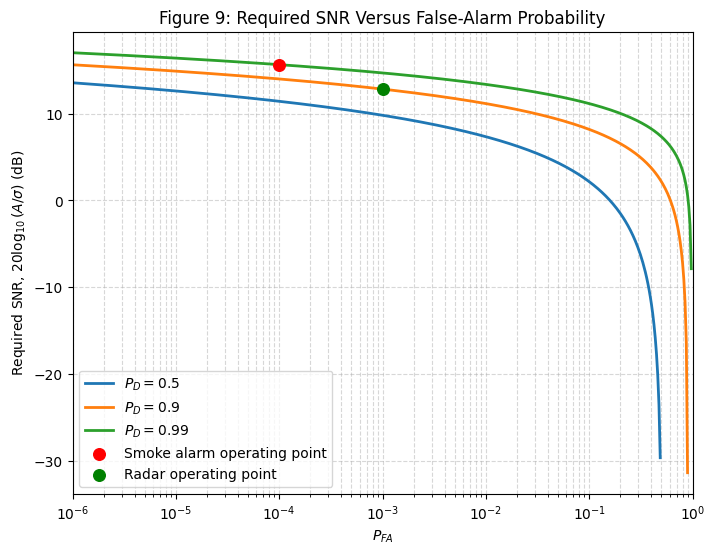


Chosen operating points
Smoke alarm: P_FA=1.0e-04, P_D=0.99, T/sigma=3.719016, A/sigma=6.045364, SNR=15.63 dB
Radar:       P_FA=1.0e-03, P_D=0.90, T/sigma=3.090232, A/sigma=4.371784, SNR=12.81 dB

Effect of adding a 1 dB threshold margin
Amplitude multiplier: 1.122018
Smoke alarm threshold increases from 3.719016 to 4.172805
Smoke alarm P_D changes from 0.990 to 0.969435
Radar threshold increases from 3.090232 to 3.467298
Radar P_D changes from 0.900 to 0.817131


In [129]:
# STEP 8: CHOOSING THE OPERATING POINT

pfa_values_8 = np.array([1e-2, 1e-3, 1e-4, 1e-6])
pd_targets_8 = [0.50, 0.90, 0.99]
z_fa_8 = stats.norm.isf(pfa_values_8)

print("Required SNR for each P_D")
print(f"{'P_FA':>12}{'P_D':>10}{'A/sigma':>15}{'SNR (dB)':>15}")

snr_results_8 = {}

for pd_target in pd_targets_8:
    z_pd = stats.norm.isf(pd_target)

    # A/sigma = Q^-1(P_FA) - Q^-1(P_D)
    amplitude_ratio = z_fa_8 - z_pd
    snr_db = 20 * np.log10(amplitude_ratio)

    snr_results_8[pd_target] = (
        amplitude_ratio,
        snr_db
    )

    for pfa, ratio, db in zip(
        pfa_values_8,
        amplitude_ratio,
        snr_db
    ):
        print(
            f"{pfa:>12.1e}"
            f"{pd_target:>10.2f}"
            f"{ratio:>15.6f}"
            f"{db:>15.6f}"
        )


# Figure 9: Required SNR curves
pfa_curve_8 = np.geomspace(1e-6, 1, 500)
z_fa_curve_8 = stats.norm.isf(pfa_curve_8)

plt.figure(figsize=(8, 6))

for pd_target in pd_targets_8:
    z_pd = stats.norm.isf(pd_target)
    ratio_curve = z_fa_curve_8 - z_pd

    valid = ratio_curve > 0

    plt.semilogx(
        pfa_curve_8[valid],
        20 * np.log10(ratio_curve[valid]),
        linewidth=2,
        label=fr"$P_D={pd_target}$"
    )

plt.xlim(1e-6, 1)


# Chosen operating points

# Smoke alarm:
# Low false alarms and high detection probability.
smoke_pfa = 1e-4
smoke_pd = 0.99
smoke_threshold = stats.norm.isf(smoke_pfa)
smoke_snr = smoke_threshold - stats.norm.isf(smoke_pd)
smoke_snr_db = 20 * np.log10(smoke_snr)

# Radar:
# relaxed false alarm rate because misses can be recovered on later scans.
radar_pfa = 1e-3
radar_pd = 0.90
radar_threshold = stats.norm.isf(radar_pfa)
radar_snr = radar_threshold - stats.norm.isf(radar_pd)
radar_snr_db = 20 * np.log10(radar_snr)

plt.scatter(
    smoke_pfa,
    smoke_snr_db,
    color="red",
    s=70,
    zorder=5,
    label="Smoke alarm operating point"
)

plt.scatter(
    radar_pfa,
    radar_snr_db,
    color="green",
    s=70,
    zorder=5,
    label="Radar operating point"
)

plt.xlabel("$P_{FA}$")
plt.ylabel("Required SNR, $20\\log_{10}(A/\\sigma)$ (dB)")
plt.title("Figure 9: Required SNR Versus False-Alarm Probability")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.show()


one_db_amplitude_margin = 10 ** (1 / 20)

smoke_threshold_margin = smoke_threshold * one_db_amplitude_margin
radar_threshold_margin = radar_threshold * one_db_amplitude_margin

smoke_pd_with_margin = q_function(
    smoke_threshold_margin - smoke_snr
)

radar_pd_with_margin = q_function(
    radar_threshold_margin - radar_snr
)

print("\nChosen operating points")
print(
    f"Smoke alarm: P_FA={smoke_pfa:.1e}, "
    f"P_D={smoke_pd:.2f}, "
    f"T/sigma={smoke_threshold:.6f}, "
    f"A/sigma={smoke_snr:.6f}, "
    f"SNR={smoke_snr_db:.2f} dB"
)

print(
    f"Radar:       P_FA={radar_pfa:.1e}, "
    f"P_D={radar_pd:.2f}, "
    f"T/sigma={radar_threshold:.6f}, "
    f"A/sigma={radar_snr:.6f}, "
    f"SNR={radar_snr_db:.2f} dB"
)

print("\nEffect of adding a 1 dB threshold margin")
print(f"Amplitude multiplier: {one_db_amplitude_margin:.6f}")
print(
    f"Smoke alarm threshold increases from "
    f"{smoke_threshold:.6f} to {smoke_threshold_margin:.6f}"
)
print(
    f"Smoke alarm P_D changes from {smoke_pd:.3f} "
    f"to {smoke_pd_with_margin:.6f}"
)
print(
    f"Radar threshold increases from "
    f"{radar_threshold:.6f} to {radar_threshold_margin:.6f}"
)
print(
    f"Radar P_D changes from {radar_pd:.3f} "
    f"to {radar_pd_with_margin:.6f}"
)

### Interpretation of Figure 9 and Operating Choices

For the smoke alarm, I would operate at $P_{FA}=10^{-4}$ and $P_D=0.99$. A miss can be life threatening, so the detector should operate toward the high detection probability portion of the ROC. This requires a threshold of $T/\sigma=3.7190$ and an SNR of about $15.63$ dB.

For the radar system, I would operate at $P_{FA}=10^{-3}$ and $P_D=0.90$. False alarms create phantom tracks and overload the operator, but a missed target may be detected on the next scan. This operating point requires $T/\sigma=3.0902$ and an SNR of about $12.81$ dB.

To tolerate a noise power estimate that is 1 dB too low, I would increase the threshold amplitude by $10^{1/20}=1.1220$, or about 12.2 percent. This increases the smoke alarm threshold from $3.7190$ to about $4.1728$ and reduces its detection probability to about $0.9694$. For the radar point, the threshold increases from $3.0902$ to about $3.4673$, reducing the detection probability to about $0.8171$.

Before selecting either operating point, the designer must know the acceptable rates of missed detections and false alarms. The safety engineer should provide this requirement for the smoke alarm, while the radar operator and tracking system designer should provide it for the surveillance system.

## Bonus A: Characteristic Functions

The characteristic function of a random variable $X$ is

$$
\phi_X(t)=E[e^{itX}].
$$

For independent random variables $X$ and $Y$,

$$
\begin{aligned}
\phi_{X+Y}(t)
&=E[e^{it(X+Y)}]\\
&=E[e^{itX}e^{itY}]\\
&=E[e^{itX}]E[e^{itY}]\\
&=\phi_X(t)\phi_Y(t).
\end{aligned}
$$

I use a Uniform$(0,1)$ variable and an Exponential$(1)$ variable. Their characteristic functions are

$$
\phi_U(t)=\frac{e^{it}-1}{it}
$$

and

$$
\phi_E(t)=\frac{1}{1-it}.
$$

The density of $U+E$ is recovered by inverse Fourier transformation. It is compared with a direct numerical convolution of the two densities.

Bonus A: Characteristic function product check
Number of samples: 200,000
Maximum absolute error: 4.288300e-03


C:\Users\chang\AppData\Local\Temp\ipykernel_13160\63483700.py:76: ComplexWarning: Casting complex values to real discards the imaginary part
  density_inverse_a[i] = (



Inverse-transform versus direct-convolution check
RMSE: 6.828585e-04


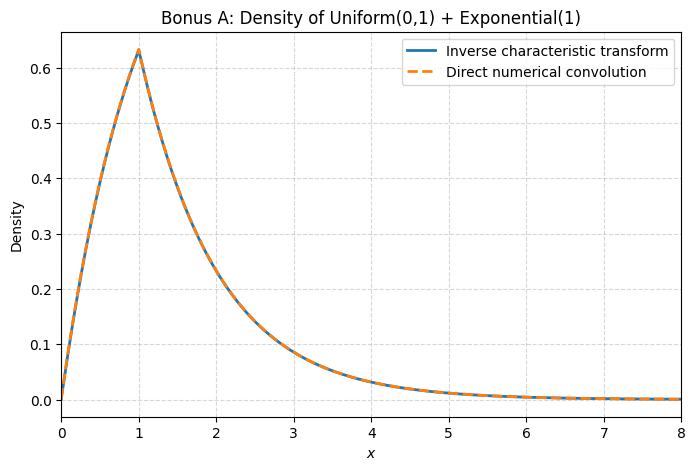


The direct convolution is cheaper for these two simple densities because it avoids evaluating a highly oscillatory inverse Fourier integral. Characteristic functions become more useful when sums involve many variables or convolution is analytically difficult.


In [130]:
# BONUS A: CHARACTERISTIC FUNCTIONS

rng_bonus_a = rng.spawn(1)[0]

# Numerical characteristic functions from samples
M_bonus_a = 200_000
t_values_a = np.linspace(-15, 15, 301)

uniform_samples_a = rng_bonus_a.random(M_bonus_a)
exponential_samples_a = rng_bonus_a.exponential(
    scale=1.0,
    size=M_bonus_a
)

def numerical_characteristic_function(samples, t_values):
    return np.mean(
        np.exp(1j * np.outer(t_values, samples)),
        axis=1
    )

phi_uniform_empirical = numerical_characteristic_function(
    uniform_samples_a,
    t_values_a
)

phi_exponential_empirical = numerical_characteristic_function(
    exponential_samples_a,
    t_values_a
)

phi_sum_empirical = numerical_characteristic_function(
    uniform_samples_a + exponential_samples_a,
    t_values_a
)

phi_product_empirical = (
    phi_uniform_empirical
    * phi_exponential_empirical
)

max_cf_error = np.max(
    np.abs(phi_sum_empirical - phi_product_empirical)
)

print("Bonus A: Characteristic function product check")
print(f"Number of samples: {M_bonus_a:,}")
print(f"Maximum absolute error: {max_cf_error:.6e}")


# Inverse transform of the exact characteristic function
# Exact characteristic functions.
# np.sinc(x) = sin(pi*x)/(pi*x).
w_values_a = np.linspace(-200, 200, 20_001)

phi_uniform_exact = (
    np.exp(1j * w_values_a / 2)
    * np.sinc(w_values_a / (2 * np.pi))
)

phi_exponential_exact = 1 / (1 - 1j * w_values_a)

phi_sum_exact = (
    phi_uniform_exact
    * phi_exponential_exact
)

x_inverse_a = np.linspace(0, 8, 401)
density_inverse_a = np.empty_like(x_inverse_a)

for i, x_value in enumerate(x_inverse_a):
    integrand = (
        phi_sum_exact
        * np.exp(-1j * w_values_a * x_value)
    )

    density_inverse_a[i] = (
    np.trapezoid(integrand, w_values_a)  / (2 * np.pi)
    )



# Direct numerical convolution
dx_a = 0.002
x_density_a = np.arange(0, 8 + dx_a, dx_a)

uniform_density_a = (
    x_density_a <= 1
).astype(float)

exponential_density_a = np.exp(-x_density_a)

convolution_density_a = (
    np.convolve(
        uniform_density_a,
        exponential_density_a
    ) * dx_a
)

x_convolution_a = np.arange(
    len(convolution_density_a)
) * dx_a

convolution_interpolated_a = np.interp(
    x_inverse_a,
    x_convolution_a,
    convolution_density_a
)

rmse_bonus_a = np.sqrt(
    np.mean(
        (density_inverse_a - convolution_interpolated_a) ** 2
    )
)

print("\nInverse-transform versus direct-convolution check")
print(f"RMSE: {rmse_bonus_a:.6e}")


# Bonus A figure
plt.figure(figsize=(8, 5))

plt.plot(
    x_inverse_a,
    density_inverse_a,
    linewidth=2,
    label="Inverse characteristic transform"
)

plt.plot(
    x_inverse_a,
    convolution_interpolated_a,
    "--",
    linewidth=2,
    label="Direct numerical convolution"
)

plt.xlabel("$x$")
plt.ylabel("Density")
plt.title("Bonus A: Density of Uniform(0,1) + Exponential(1)")
plt.xlim(0, 8)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

print(
    "\nThe direct convolution is cheaper for these two simple densities "
    "because it avoids evaluating a highly oscillatory inverse Fourier "
    "integral. Characteristic functions become more useful when sums "
    "involve many variables or convolution is analytically difficult."
)

## Bonus B: A Distribution with No Mean

Let

$$
Z=\frac{X}{Y},
$$

where $X$ and $Y$ are independent standard Gaussian random variables.

The transformation

$$
x=zy
$$

has Jacobian magnitude $|y|$. Therefore,

$$
\begin{aligned}
f_Z(z)
&=\int_{-\infty}^{\infty}
f_X(zy)f_Y(y)|y|\,dy\\
&=\frac{1}{2\pi}
\int_{-\infty}^{\infty}
e^{-(z^2+1)y^2/2}|y|\,dy\\
&=\frac{1}{\pi(1+z^2)}.
\end{aligned}
$$

Thus, $Z$ has the standard Cauchy distribution.

The Cauchy distribution has no defined mean or variance because its tails decay too slowly. Its median is zero, however, because the distribution is symmetric about zero. Therefore, the sample mean does not become more reliable as the sample size increases, while the sample median converges toward zero.

Bonus B: Cauchy sample mean and median
           N         Sample mean       Sample median
       1,000           -0.552670           -0.114751
      10,000           -1.354235           -0.018407
     100,000           -0.130296           -0.000521
   1,000,000           -1.980856            0.000391


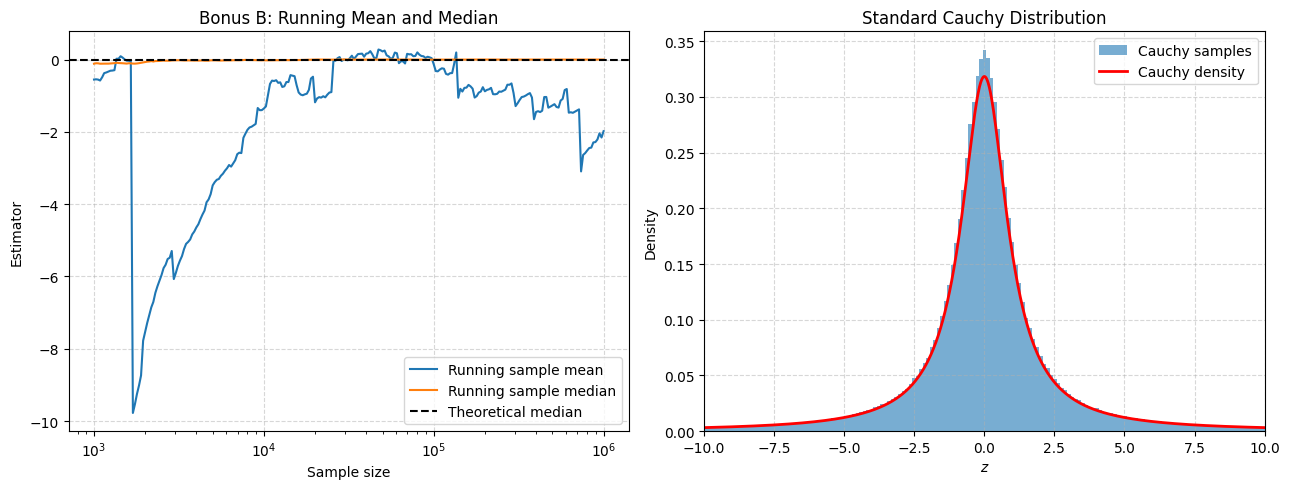


The Cauchy sample mean does not settle because the population mean does not exist.Extremely large observations remain possible and can change the mean by several units even after many samples.The median is stable because the Cauchy distribution is symmetric about zero.For Cauchy-like measurement noise, the median or another robust estimator should be used instead of the ordinary sample mean.


In [131]:
# BONUS B: RATIO OF TWO GAUSSIANS

rng_bonus_b = rng.spawn(1)[0]

N_bonus_b = 1_000_000

normal_numerator_b = rng_bonus_b.standard_normal(N_bonus_b)
normal_denominator_b = rng_bonus_b.standard_normal(N_bonus_b)

# The probability that the denominator is exactly zero is zero
# mathematically, but this check protects the computation.
valid_b = normal_denominator_b != 0

cauchy_samples_b = (
    normal_numerator_b[valid_b]
    / normal_denominator_b[valid_b]
)

sample_sizes_b = np.array([
    1_000,
    10_000,
    100_000,
    1_000_000
])

print("Bonus B: Cauchy sample mean and median")
print(f"{'N':>12}{'Sample mean':>20}{'Sample median':>20}")

for n in sample_sizes_b:
    current_samples_b = cauchy_samples_b[:n]

    print(
        f"{n:>12,}"
        f"{np.mean(current_samples_b):>20.6f}"
        f"{np.median(current_samples_b):>20.6f}"
    )


# Running mean and median
plot_sizes_b = np.unique(
    np.logspace(3, 6, 250).astype(int)
)

running_mean_b = np.array([
    np.mean(cauchy_samples_b[:n])
    for n in plot_sizes_b
])

running_median_b = np.array([
    np.median(cauchy_samples_b[:n])
    for n in plot_sizes_b
])


# Cauchy density and figure
x_b = np.linspace(-10, 10, 2_000)
cauchy_pdf_b = 1 / (np.pi * (1 + x_b**2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    plot_sizes_b,
    running_mean_b,
    label="Running sample mean"
)

axes[0].plot(
    plot_sizes_b,
    running_median_b,
    label="Running sample median"
)

axes[0].axhline(
    0,
    color="black",
    linestyle="--",
    label="Theoretical median"
)

axes[0].set_xscale("log")
axes[0].set_xlabel("Sample size")
axes[0].set_ylabel("Estimator")
axes[0].set_title("Bonus B: Running Mean and Median")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend()


axes[1].hist(
    cauchy_samples_b,
    bins=np.linspace(-10, 10, 160),
    density=True,
    alpha=0.6,
    label="Cauchy samples"
)

axes[1].plot(
    x_b,
    cauchy_pdf_b,
    "r-",
    linewidth=2,
    label="Cauchy density"
)

axes[1].set_xlim(-10, 10)
axes[1].set_xlabel("$z$")
axes[1].set_ylabel("Density")
axes[1].set_title("Standard Cauchy Distribution")
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend()

fig.tight_layout()
plt.show()


print(
    "\nThe Cauchy sample mean does not settle because the population mean does not exist."
    "Extremely large observations remain possible and can change the mean by several units even after many samples."
    "The median is stable because the Cauchy distribution is symmetric about zero."
    "For Cauchy-like measurement noise, the median or another robust estimator should be used instead of the ordinary sample mean."
)